<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Datos Masivos II · PRÁCTICA 4</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">BindingDB: limpieza y matriz de interacciones</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

## Propósito

Este notebook es el **puente** entre el análisis exploratorio (`BindingDB_EDA.ipynb`) y el sistema de recomendación. Toma el volcado completo de BindingDB ya tipificado por el EDA y entrega una **matriz de interacciones proteína–ligando** lista para alimentar un modelo, más las dos tablas de atributos que hacen falta para la parte de contenido de un modelo híbrido.

No se entrena ni se evalúa ningún modelo aquí. Tampoco se repiten los diagnósticos del EDA: **cada decisión de limpieza cita la sección del EDA que la justifica**, para que se pueda auditar sin volver a calcular nada.

### Qué entrega

| Archivo | Una fila por | Para qué sirve |
|---|---|---|
| `data/processed/rec_interacciones.parquet` | par (proteína, ligando) | la matriz: usuario, ítem y *rating* |
| `data/processed/rec_ligandos.parquet` | ligando | atributos de ítem (SMILES e identificadores) |
| `data/processed/rec_targets.parquet` | proteína | atributos de usuario (secuencia y nombre) |
| `data/processed/rec_meta.json` | — | el embudo y los parámetros usados, para reproducibilidad |

### Las dos decisiones de diseño

1. **El usuario es la proteína canónica (`uniprot1`), no el `Target Name`.** El `Target Name` distingue construcciones y mutantes: el EDA (§8, *Nombres, construcciones y proteínas canónicas*) encontró que una sola accession llega a tener **60 nombres distintos** (el receptor del factor de crecimiento epidérmico, `P00533`). Usar el nombre partiría a ese usuario en 60 usuarios con pocos datos cada uno.
2. **Se entregan dos columnas de *rating*, no una.** `pIC50` es continuo y sirve para predecir un valor (RMSE); `activo` es binario y sirve para ordenar recomendaciones (Precision@k, Recall@k, NDCG). La razón de entregar ambas es que **no son redundantes**: hay pares cuyo único dato es censurado (`>10000`), que no dan un valor puntual pero sí dicen con certeza que la molécula no se une. Esos pares tienen `activo` pero no `pIC50`.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">0. Decisiones de limpieza</span></div>

Todas las decisiones están en la celda de parámetros de la sección 1, en un solo bloque, para poder rehacer la entrega con otro criterio cambiando una línea.

| Decisión | Valor | Por qué |
|---|---|---|
| Tipo de medición | `IC50` | Lo indican las instrucciones de la práctica. Es además el 68% de las filas (EDA §5, *Medición por fila*). |
| Especie | sufijo `_HUMAN` de UniProt | **No** se filtra por la columna de organismo: es texto libre y usa al menos tres etiquetas para humano (sección 3.2). |
| Nº de cadenas | solo targets de 1 cadena | Un complejo multicadena no es "una proteína"; mezclarlo con monómeros haría ambiguo al usuario (EDA §8, *Complejos multicadena*). |
| Identidad del ligando | `InChIKey[:25]` | Agrupa variantes de **protonación** (la misma molécula como sal o neutra) pero conserva los **estereoisómeros** separados, que sí pueden tener afinidades distintas (EDA §7, *Anatomía del InChIKey*). |
| Valores censurados | se traducen a `activo` cuando son concluyentes | Un `>10000` no es un valor puntual, pero sí es un **negativo informativo** (EDA §5, *Valores censurados*). El detalle está en la sección 4. |
| Valores imposibles | se descarta `p` fuera de `[2, 12]` | Afinidades por debajo de 1 pM o por encima de 10 mM suelen ser errores de unidades en la fuente (EDA §5, *Valores extremos o físicamente dudosos*). |
| Pares repetidos | **mediana** de las mediciones exactas | El mismo par se mide varias veces y los valores difieren; la mediana resiste los valores atípicos. La dispersión se conserva en columnas aparte (EDA §9, *Posibles registros duplicados*). |

> **Sobre el sesgo que no se puede limpiar.** El EDA (§6, *Origen por medición*) mostró que el tipo de medición está **confundido con la fuente**: el IC50 es el formato de las patentes. Al quedarnos solo con IC50 heredamos ese sesgo, y ninguna limpieza lo arregla. Lo que sí se puede hacer es dejarlo visible: cada par lleva una columna `alguna_patente` y el año de publicación, para que el modelo pueda controlarlo o al menos reportarlo.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Entorno y parámetros</span></div>

In [1]:
from pathlib import Path
import json, re, time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 60)

# ----------------------------- RUTAS -----------------------------
PROC      = Path("data/processed")
EDA_CACHE = PROC / "bindingdb_eda.parquet"            # salida del notebook de EDA
EDA_SEQ   = PROC / "bindingdb_eda_secuencias.parquet"
OUT_INT   = PROC / "rec_interacciones.parquet"
OUT_LIG   = PROC / "rec_ligandos.parquet"
OUT_TGT   = PROC / "rec_targets.parquet"
OUT_META  = PROC / "rec_meta.json"
FIG_DIR   = Path("figs/limpieza"); FIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------- PARÁMETROS DE LIMPIEZA ----------------------
# Esto es lo único que hay que tocar para rehacer la entrega con otro criterio.
MEDICION     = "IC50"   # tipo de afinidad que hace de rating (instrucciones de la práctica)
ESPECIE      = "HUMAN"  # sufijo del entry name de UniProt; None = todas las especies
SOLO_1_CADENA = True    # quedarse solo con targets de una sola cadena proteica
UMBRAL       = 6.0      # pIC50 >= UMBRAL  =>  activo.  6.0 = 1 µM = corte habitual
P_MIN, P_MAX = 2.0, 12.0  # descartar afinidades físicamente dudosas (EDA §5, *Valores extremos o físicamente dudosos*)
LIG_ID_LEN   = 25       # 25 = agrupa protonación | 27 = InChIKey completo | 14 = esqueleto sin estereo
RANGO_DISC   = 1.0      # un par con rango mayor a este (en log) se marca discordante
SEMILLA      = 0

# Patrón oficial de accession de UniProt [2]
RE_UNIPROT  = r"[OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2}"
RE_INCHIKEY = r"[A-Z]{14}-[A-Z]{8}[SN][A-Z]-[A-Z]"   # EDA §7, *Anatomía del InChIKey*
EXACTOS     = {"=", "~"}   # calificadores que se consideran un valor puntual

# ----------------------------- ESTILO -----------------------------
# Misma paleta que el EDA, validada para daltonismo (orden fijo, no se cicla)
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
CAT = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
GRIS = "#8a8984"
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "azul", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False,
    "axes.prop_cycle": cycler(color=CAT),
})

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight")
    plt.show()

def pct(a, b):
    return 100 * a / b if b else float("nan")

H = {}        # hallazgos clave para el resumen final
EMBUDO = []   # (paso, filas restantes) para la trazabilidad

print("Entrada:", EDA_CACHE, "| existe:", EDA_CACHE.exists(),
      f"| {EDA_CACHE.stat().st_size/1e6:.0f} MB" if EDA_CACHE.exists() else "")
print(f"Rating = {MEDICION} | especie = {ESPECIE} | umbral de actividad = pIC50 {UMBRAL}")

Entrada: data\processed\bindingdb_eda.parquet | existe: True | 189 MB
Rating = IC50 | especie = HUMAN | umbral de actividad = pIC50 6.0


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Carga</span></div>

Se leen del parquet del EDA solo las columnas que esta etapa necesita. Las secuencias viven en una tabla aparte, indexadas por `seq_id1`, para no repetir ~600 caracteres en millones de filas.

In [2]:
COLS = ["rsid", "inchikey", "smiles", "lig_name", "target", "organism",
        "uniprot1", "sp_name1", "sp_entry1", "n_chains", "seq_id1",
        "pub_date", "source", "id_cid", "id_chembl", MEDICION, f"{MEDICION}_qual"]

t0 = time.time()
bd = pd.read_parquet(EDA_CACHE, columns=COLS)
seqs = pd.read_parquet(EDA_SEQ)
EMBUDO.append(("Filas en el EDA", len(bd)))

print(f"Filas: {len(bd):,} | columnas: {bd.shape[1]} | secuencias: {len(seqs):,} "
      f"| RAM: {bd.memory_usage(deep=True).sum()/1e9:.2f} GB | {time.time()-t0:.0f} s")

Filas: 3,243,660 | columnas: 17 | secuencias: 11,018 | RAM: 1.44 GB | 8 s


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Filtros: de qué universo se parte</span></div>

### 3.1 Quedarse con las filas que tienen la medición elegida

In [3]:
def paso(nombre, d):
    """Registra cuántas filas sobreviven a cada filtro."""
    EMBUDO.append((nombre, len(d)))
    return d

d = paso(f"Con {MEDICION} medido", bd[bd[MEDICION].notna()].copy())
print(f"Filas con {MEDICION}: {len(d):,} ({pct(len(d), len(bd)):.1f}% del archivo)")
print(f"Filas que se dejan ir por no traer {MEDICION}: {len(bd)-len(d):,}")

Filas con IC50: 2,220,490 (68.5% del archivo)
Filas que se dejan ir por no traer IC50: 1,023,170


### 3.2 La especie: por qué no se usa la columna de organismo

La columna de organismo de BindingDB es **texto libre del curador** (EDA §8, *Organismos y especie según UniProt*). Antes de filtrar con ella conviene mirar cuántas formas de escribir "humano" contiene, y compararla con el **sufijo del *entry name* de UniProt** (`..._HUMAN`), que es una anotación controlada [2].

In [4]:
org = d["organism"].astype("string")
menciona_humano = org.str.contains(r"human|sapiens", case=False, na=False)
suf = d["sp_entry1"].astype("string").str.rsplit("_", n=1).str[-1]
es_humano_uniprot = suf.eq("HUMAN")

print("Etiquetas de organismo que son humano (texto libre):")
display(org[menciona_humano & es_humano_uniprot].value_counts().head(5).rename("filas").to_frame())

solo_texto = int((es_humano_uniprot & org.ne("Homo sapiens")).sum())
solo_uniprot = int((~es_humano_uniprot & org.eq("Homo sapiens")).sum())
print(f'Filas humanas (según UniProt) que NO dicen exactamente "Homo sapiens": {solo_texto:,}')
print(f'Filas que dicen "Homo sapiens" pero cuyo UniProt no es humano           : {solo_uniprot:,}')
print("\nFuentes de las filas etiquetadas solo como 'Human':",
      d.loc[org.eq("Human"), "source"].value_counts().head(3).to_dict())
H["Filas humanas que un filtro por texto perdería"] = f"{solo_texto:,}"

Etiquetas de organismo que son humano (texto libre):


,filas
organism,
Homo sapiens,1721483
Human,163763
Homo sapiens (Human),524


Filas humanas (según UniProt) que NO dicen exactamente "Homo sapiens": 165,017
Filas que dicen "Homo sapiens" pero cuyo UniProt no es humano           : 652

Fuentes de las filas etiquetadas solo como 'Human': {'US Patent': 143913, 'ChEMBL': 15137, 'PubChem': 2301}


**Por qué importa.** Filtrar con `organism == "Homo sapiens"` descarta en silencio las filas etiquetadas `"Human"` y `"Homo sapiens (Human)"`. No es un error inocuo: esas filas vienen **mayoritariamente de patentes**, así que el filtro ingenuo no quita datos al azar, sino que **recorta una fuente entera** y agrava el sesgo de procedencia que el EDA ya había detectado (§6, *Origen por medición*).

Por eso la especie se decide con el sufijo de UniProt. Las discrepancias en el otro sentido (filas que dicen "Homo sapiens" pero cuyo UniProt es de otra especie) son unos cientos, y se resuelven a favor de UniProt por la misma razón: es la anotación controlada.

In [5]:
if ESPECIE:
    d = paso(f"Target de la especie {ESPECIE}", d[suf.eq(ESPECIE).reindex(d.index, fill_value=False)])
if SOLO_1_CADENA:
    d = paso("Proteína de una sola cadena", d[d["n_chains"] == 1])
print(f"Filas: {len(d):,} | targets (accession): {d['uniprot1'].nunique():,}")

Filas: 1,784,544 | targets (accession): 3,457


### 3.3 Normalizar la accession de UniProt

El EDA no revisó el **formato** de la accession. Se valida contra el patrón oficial [2] y se revisan los casos raros uno por uno antes de descartarlos: en una tabla de millones de filas, "raro" puede ser un problema sistemático o pueden ser tres celdas.

In [6]:
u = d["uniprot1"].astype("string").str.strip()
con_espacio = u.str.contains(" ", na=False)
print(f"Celdas con más de una accession: {int(con_espacio.sum()):,}")
if con_espacio.any():
    display(u[con_espacio].value_counts().rename("filas").to_frame())
    # El mismo accession repetido se colapsa; dos distintos son ambiguos y se dejan como faltante.
    u.loc[con_espacio] = u[con_espacio].map(
        lambda v: (lambda s: s.pop() if len(s) == 1 else pd.NA)(set(v.split())))

valido = u.str.fullmatch(RE_UNIPROT).fillna(False)
print(f"Accessions con formato oficial: {pct(valido.sum(), len(u)):.4f}% "
      f"| se descartan {int((~valido).sum()):,} filas")
d["target_id"] = u
d = paso("Accession UniProt válida", d[valido])

Celdas con más de una accession: 3


,filas
uniprot1,
Q86V67 P27815,2
P24462 P24462,1


Accessions con formato oficial: 99.9999% | se descartan 2 filas


**Interpretación.** El formato es correcto en prácticamente todas las filas. Los únicos casos raros son tres: una celda con la misma accession escrita dos veces (`P24462 P24462`, que se colapsa sin pérdida de información) y dos filas con **dos accessions distintas** en la cadena 1, que son genuinamente ambiguas y se descartan. Tres filas de 1.8 millones no mueven ningún resultado, pero valía la pena mirarlas en vez de aplicar el filtro a ciegas.

### 3.4 Validar la identidad del ligando y descartar valores imposibles

In [7]:
ik = d["inchikey"].astype("string")
d = paso("InChIKey con formato válido", d[ik.str.fullmatch(RE_INCHIKEY).fillna(False)])
d = paso(f"{MEDICION} > 0", d[d[MEDICION] > 0])

d["p"] = 9 - np.log10(d[MEDICION])
fuera = ~d["p"].between(P_MIN, P_MAX)
print(f"Valores fuera de p ∈ [{P_MIN}, {P_MAX}]: {int(fuera.sum()):,} "
      f"({pct(fuera.sum(), len(d)):.3f}%)  — EDA §5, *Valores extremos o físicamente dudosos*")
d = paso(f"p dentro de [{P_MIN}, {P_MAX}]", d[~fuera])
print(f"Filas: {len(d):,}")

Valores fuera de p ∈ [2.0, 12.0]: 1,620 (0.091%)  — EDA §5, *Valores extremos o físicamente dudosos*


Filas: 1,782,559


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. El rating: pIC50 y los valores censurados</span></div>

La escala `p` comprime cinco órdenes de magnitud en un número manejable y además **invierte el sentido**: `pIC50 = 9 − log₁₀(IC50 en nM)`, así que **más grande es más potente**, que es la dirección que espera un sistema de recomendación (un *rating* alto = algo bueno).

El problema son los **calificadores**. Según el EDA (§5, *Valores censurados*), una parte importante de los IC50 no es un número sino una cota: `>10000` significa "no se detectó efecto a la concentración máxima probada". Tirarlos pierde información valiosa, porque **son los únicos negativos explícitos del dataset**, pero tratarlos como si fueran un valor puntual es inventar datos.

### 4.1 Cuándo una cota es concluyente

La regla depende del umbral de actividad, y es puramente lógica:

- `> X` quiere decir `IC50 > X`, o sea `p < p(X)`. **Concluye "inactivo" solo si `p(X) ≤ UMBRAL`**. Un `>10000` nM (p < 5) con umbral 6 es inactivo sin duda; un `>100` nM (p < 7) no dice nada, porque el valor real podría estar a cualquier lado de 6.
- `< X` quiere decir `IC50 < X`, o sea `p > p(X)`. **Concluye "activo" solo si `p(X) ≥ UMBRAL`**.
- Lo que no concluye nada se descarta: no aporta ni el valor ni la etiqueta.

In [8]:
q = d[f"{MEDICION}_qual"].astype("string").fillna("=")
print("Calificadores presentes:", q.value_counts().to_dict())

d["exacta"]  = q.isin(EXACTOS)
cens_inact   = q.eq(">") & (d["p"] <= UMBRAL)   # cota superior por debajo del umbral
cens_act     = q.eq("<") & (d["p"] >= UMBRAL)   # cota inferior por encima del umbral
indet        = ~(d["exacta"] | cens_inact | cens_act)

resumen = pd.DataFrame({
    "filas": [int(d["exacta"].sum()), int(cens_act.sum()), int(cens_inact.sum()), int(indet.sum())],
    "qué aporta": ["valor puntual de pIC50", "etiqueta activo", "etiqueta inactivo", "nada: se descarta"],
}, index=["exactas", f"censuradas '<' concluyentes", f"censuradas '>' concluyentes", "censuradas no concluyentes"])
resumen["%"] = (100 * resumen["filas"] / len(d)).round(2)
display(resumen)

d["act_cens"] = np.where(cens_act, 1.0, np.where(cens_inact, 0.0, np.nan))
d = paso("Sin censurados no concluyentes", d[~indet])
H["Negativos explícitos recuperados de los censurados"] = f"{int(cens_inact.sum()):,}"

Calificadores presentes: {'=': 1389698, '>': 228136, '<': 164725}


,filas,qué aporta,%
exactas,1389698,valor puntual de pIC50,77.96
censuradas '<' concluyentes,154489,etiqueta activo,8.67
censuradas '>' concluyentes,214162,etiqueta inactivo,12.01
censuradas no concluyentes,24210,nada: se descarta,1.36


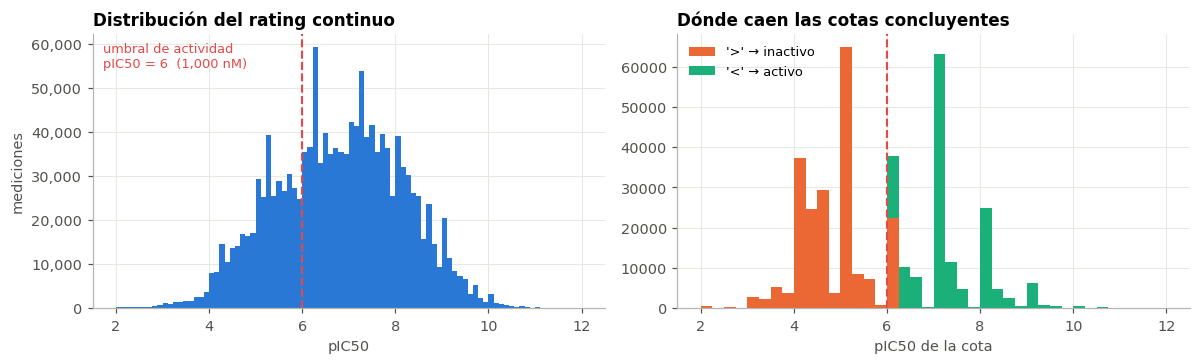

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.hist(d.loc[d["exacta"], "p"], bins=90, color=AZUL, label="mediciones exactas")
ax.axvline(UMBRAL, color=ROJO, lw=1.4, ls="--")
ax.annotate(f"umbral de actividad\npIC50 = {UMBRAL:g}  ({10**(9-UMBRAL):,.0f} nM)",
            xy=(0.02, 0.97), xycoords="axes fraction", color=ROJO, fontsize=8.5,
            va="top", ha="left")
ax.set_xlabel("pIC50"); ax.set_ylabel("mediciones")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Distribución del rating continuo")

ax = axes[1]
cotas = pd.DataFrame({
    "'>' (inactivo)": d.loc[cens_inact.reindex(d.index, fill_value=False), "p"],
    "'<' (activo)":   d.loc[cens_act.reindex(d.index, fill_value=False), "p"],
})
ax.hist([cotas["'>' (inactivo)"].dropna(), cotas["'<' (activo)"].dropna()], bins=40,
        stacked=True, color=[NARANJA, AQUA], label=["'>' → inactivo", "'<' → activo"])
ax.axvline(UMBRAL, color=ROJO, lw=1.4, ls="--")
ax.set_xlabel("pIC50 de la cota"); ax.set_title("Dónde caen las cotas concluyentes")
ax.legend(loc="upper left", fontsize=8.5)
guardar(fig, "01_rating")

**Interpretación.** El rating continuo se distribuye alrededor de pIC50 ≈ 6–7, como ya había visto el EDA (§5, *Distribución de la afinidad*), con los picos en valores redondos que delatan cortes de ensayo. El umbral de 1 µM cae cerca de la moda, lo cual es deseable: parte la muestra en dos clases de tamaño comparable en vez de dejar una clase minoritaria.

El panel derecho muestra por qué la regla de la sección 4.1 no es pedantería: las cotas `>` se acumulan **a la izquierda** del umbral y las `<` **a la derecha**, es decir, la gran mayoría de los censurados sí es concluyente. Solo una minoría cae del lado equivocado de la línea y es la que se descarta.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Identidad del usuario y del ítem</span></div>

El usuario ya está decidido (`target_id` = accession de UniProt). Para el ítem, el EDA (§7, *Anatomía del InChIKey*) mostró que el InChIKey tiene estructura: los primeros 14 caracteres son el **esqueleto** (las conexiones), el segundo bloque codifica **estereoquímica** y el último carácter, la **protonación**. Recortar a 25 caracteres junta la misma molécula registrada como sal y como neutra, y deja separados los estereoisómeros.

In [10]:
d["lig_id"] = d["inchikey"].astype("string").str[:LIG_ID_LEN]
n_ik, n_lig = d["inchikey"].nunique(), d["lig_id"].nunique()
n_tgt = d["target_id"].nunique()

print(f"Ligandos con InChIKey completo : {n_ik:,}")
print(f"Ligandos con lig_id[:{LIG_ID_LEN}]        : {n_lig:,}   (se fusionaron {n_ik-n_lig:,})")
print(f"Targets (accession UniProt)    : {n_tgt:,}")
print(f"Nombres de target distintos    : {d['target'].nunique():,}  "
      f"→ {d['target'].nunique()/n_tgt:.1f} nombres por accession en promedio")
H["Targets (usuarios)"] = f"{n_tgt:,}"
H["Ligandos (ítems)"] = f"{n_lig:,}"

Ligandos con InChIKey completo : 833,085
Ligandos con lig_id[:25]        : 832,751   (se fusionaron 334)
Targets (accession UniProt)    : 3,444
Nombres de target distintos    : 4,231  → 1.2 nombres por accession en promedio


**Interpretación.** Agrupar por protonación fusiona **pocos** ligandos en este subconjunto: casi todos los compuestos con IC50 humano están registrados una sola vez en un estado de ionización. El recorte se deja porque es correcto y gratuito, pero conviene ser honestos: **no es una decisión que cambie el resultado**. Si se prefiere el InChIKey completo, basta con poner `LIG_ID_LEN = 27` y la entrega será prácticamente idéntica.

La decisión del usuario tampoco resulta tan drástica como la hacía parecer el EDA: en este subconjunto hay **1.2 nombres de target por accession** en promedio, no las decenas del caso extremo de `P00533`. La razón es que los mutantes y las construcciones se concentran en unos pocos targets muy estudiados. Dicho de otro modo, usar `Target Name` habría partido sobre todo a los usuarios con **más** datos, que son precisamente los que sostienen a un modelo colaborativo, así que la decisión sigue siendo la correcta aunque el promedio sea modesto.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Agregar los pares repetidos</span></div>

Un mismo par proteína–ligando aparece varias veces: distintos artículos, distintos laboratorios, distintos ensayos. El EDA (§9, *Posibles registros duplicados*) encontró que esos valores repetidos **difieren**, a veces en más de un orden de magnitud. Hay que colapsarlos a una fila por par, y la pregunta es qué hacer con la discrepancia.

La decisión es **resumir con la mediana pero no esconder la dispersión**: cada par lleva el rango de sus mediciones y una bandera `discordante`. Así, quien entrene el modelo puede decidir si confía en esos pares, los pondera menos o los excluye, sin tener que volver al archivo de 9 GB.

In [11]:
d["anio"] = d["pub_date"].dt.year
d["patente"] = d["source"].astype("string").str.contains(r"patent|wipo", case=False, na=False)

llaves = ["target_id", "lig_id"]
g = d.groupby(llaves, observed=True)
I = pd.DataFrame({
    "n_mediciones":   g.size(),
    "anio_min":       g["anio"].min(),
    "anio_max":       g["anio"].max(),
    "alguna_patente": g["patente"].any(),
})

ex = d[d["exacta"]].groupby(llaves, observed=True)["p"]
I = I.join(pd.DataFrame({"n_exactas": ex.size(), "pIC50": ex.median().round(3),
                         "pIC50_min": ex.min().round(3), "pIC50_max": ex.max().round(3)}))
ce = d[~d["exacta"]].groupby(llaves, observed=True)["act_cens"]
I = I.join(pd.DataFrame({"n_censuradas": ce.size(), "_frac_act_cens": ce.mean()}))

for c in ["n_exactas", "n_censuradas"]:
    I[c] = I[c].fillna(0).astype("int32")
for c in ["anio_min", "anio_max"]:
    I[c] = I[c].astype("Int16")   # entero con nulos: hay pares sin fecha de publicación válida
print(f"Mediciones: {len(d):,}  →  pares únicos: {len(I):,}")
print(f"Pares con más de una medición: {pct((I.n_mediciones > 1).sum(), len(I)):.1f}%  "
      f"| máximo de mediciones en un par: {I.n_mediciones.max():,}")
print(f"Pares sin año de publicación: {int(I.anio_min.isna().sum()):,} "
      f"({pct(I.anio_min.isna().sum(), len(I)):.1f}%) — quedan fuera de una partición temporal "
      f"| rango: {int(I.anio_min.min())}–{int(I.anio_max.max())}")

Mediciones: 1,758,349  →  pares únicos: 1,250,494
Pares con más de una medición: 21.9%  | máximo de mediciones en un par: 409
Pares sin año de publicación: 36,915 (3.0%) — quedan fuera de una partición temporal | rango: 1976–2026


### 6.1 Resolver el rating de cada par

El orden de preferencia es: si el par tiene **alguna medición exacta**, manda la mediana de las exactas. Si su único dato son cotas, el par se queda **sin `pIC50`** (no hay valor puntual que inventar) pero **conserva su etiqueta `activo`**.

In [12]:
I["solo_censurado"] = I["pIC50"].isna()
I["activo"] = np.where(I["pIC50"].notna(), I["pIC50"] >= UMBRAL,
                       I["_frac_act_cens"] >= 0.5).astype("int8")
# Cotas que se contradicen entre sí en el mismo par (unas dicen activo y otras inactivo)
I["conflicto_cotas"] = I["solo_censurado"] & I["_frac_act_cens"].between(0.001, 0.999)
I["rango_log"] = (I["pIC50_max"] - I["pIC50_min"]).round(3)
I["discordante"] = (I["rango_log"] > RANGO_DISC).fillna(False)
I = I.drop(columns="_frac_act_cens").reset_index()

con_varias = I["n_exactas"] > 1
tabla = pd.DataFrame({
    "pares": [len(I), int(I.solo_censurado.sum()), int(con_varias.sum()),
              int(I.discordante.sum()), int(I.conflicto_cotas.sum())],
}, index=["total", "sin pIC50 (solo cotas)", "con más de una medición exacta",
          f"discordantes (rango > {RANGO_DISC:g} log)", "con cotas contradictorias"])
tabla["% del total"] = (100 * tabla["pares"] / len(I)).round(2)
display(tabla)

print(f"Entre los pares con varias mediciones exactas, {pct(I.discordante.sum(), con_varias.sum()):.1f}% "
      f"son discordantes.")
print(f"Balance de clases: activo = {pct((I.activo == 1).sum(), len(I)):.1f}% | "
      f"inactivo = {pct((I.activo == 0).sum(), len(I)):.1f}%")
H["Pares (celdas con dato)"] = f"{len(I):,}"
H["Pares cuyo único dato es una cota"] = f"{pct(I.solo_censurado.sum(), len(I)):.1f}%"
H["Pares discordantes (de los repetidos)"] = f"{pct(I.discordante.sum(), con_varias.sum()):.1f}%"

,pares,% del total
total,1250494,100.00
sin pIC50 (solo cotas),258610,20.68
con más de una medición exacta,215204,17.21
discordantes (rango > 1 log),42606,3.41
con cotas contradictorias,1148,0.09


Entre los pares con varias mediciones exactas, 19.8% son discordantes.
Balance de clases: activo = 61.9% | inactivo = 38.1%


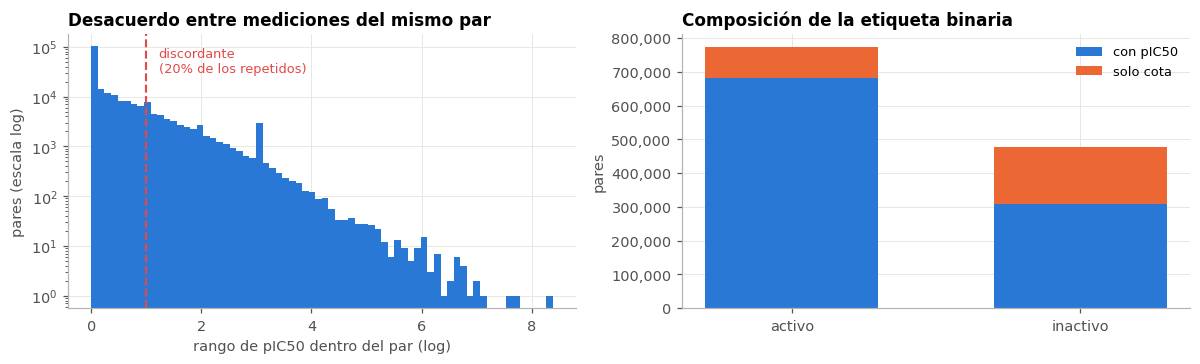

Los pares cuyo único dato es una cota son 64.9% inactivos y 35.1% activos.
De toda la clase inactiva, 35.2% existe solo gracias a las cotas.
Si se descartaran los censurados, la clase inactiva pasaría de 38.1% a 31.2% de los pares.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
r = I.loc[con_varias, "rango_log"]
ax.hist(r, bins=70, color=AZUL)
ax.axvline(RANGO_DISC, color=ROJO, lw=1.4, ls="--")
ax.annotate(f"discordante\n({pct(I.discordante.sum(), con_varias.sum()):.0f}% de los repetidos)",
            xy=(RANGO_DISC, ax.get_ylim()[1]*0.9), xytext=(8, 0), textcoords="offset points",
            color=ROJO, fontsize=8.5, va="top")
ax.set_yscale("log")
ax.set_xlabel("rango de pIC50 dentro del par (log)"); ax.set_ylabel("pares (escala log)")
ax.set_title("Desacuerdo entre mediciones del mismo par")

ax = axes[1]
comp = pd.DataFrame({
    "activo":   [int(((I.activo == 1) & ~I.solo_censurado).sum()), int(((I.activo == 1) & I.solo_censurado).sum())],
    "inactivo": [int(((I.activo == 0) & ~I.solo_censurado).sum()), int(((I.activo == 0) & I.solo_censurado).sum())],
}, index=["con pIC50", "solo cota"])
abajo = np.zeros(2)
for (etq, fila), color in zip(comp.iterrows(), [AZUL, NARANJA]):
    ax.bar(comp.columns, fila.values, bottom=abajo, color=color, label=etq, width=0.6)
    abajo += fila.values
ax.set_ylabel("pares"); ax.set_title("Composición de la etiqueta binaria")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(fontsize=8.5)
guardar(fig, "02_pares")

sc, ina = I[I.solo_censurado], I[I.activo == 0]
print(f"Los pares cuyo único dato es una cota son {pct((sc.activo == 0).sum(), len(sc)):.1f}% inactivos "
      f"y {pct((sc.activo == 1).sum(), len(sc)):.1f}% activos.")
print(f"De toda la clase inactiva, {pct(ina.solo_censurado.sum(), len(ina)):.1f}% existe solo gracias a las cotas.")
sin_cens = I[~I.solo_censurado]
print(f"Si se descartaran los censurados, la clase inactiva pasaría de "
      f"{pct((I.activo == 0).sum(), len(I)):.1f}% a {pct((sin_cens.activo == 0).sum(), len(sin_cens)):.1f}% "
      f"de los pares.")

**Interpretación.** El desacuerdo entre laboratorios no es anecdótico: alrededor de uno de cada cinco pares medidos más de una vez tiene un rango mayor a un orden de magnitud. Eso fija un **techo realista para el error del modelo**: no tiene sentido perseguir un RMSE más bajo que el ruido experimental del propio dataset, que es del orden de 0.5–1 unidades de pIC50. Vale la pena decirlo en la evaluación.

El panel derecho es el argumento de las dos columnas. Las cotas **se inclinan hacia el lado inactivo**, en una proporción de unos dos a uno, y acaban sosteniendo **poco más de un tercio de toda la clase inactiva**. Eso importa porque los inactivos son justo lo que un dataset de afinidades tiende a no tener: nadie publica un artículo sobre las moléculas que no funcionaron. Descartar los censurados no destruiría la clase minoritaria, pero sí la encogería varios puntos y haría el problema artificialmente más fácil de lo que es.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Tablas de atributos para la parte de contenido</span></div>

Un modelo híbrido necesita describir usuarios e ítems por lo que *son*, no solo por lo que han interactuado. Aquí no se calculan los descriptores finales (los *fingerprints* moleculares requieren RDKit, que no está en este entorno, y los de secuencia dependen del modelo), pero se entregan las **materias primas** en dos tablas limpias, una fila por entidad.

### 7.1 Ligandos

In [14]:
# SMILES representativo: el más frecuente de cada lig_id (una molécula admite varias escrituras, EDA §7, *Anatomía del InChIKey*)
rep = (d.groupby(["lig_id", "smiles"], observed=True).size().rename("n").reset_index()
        .sort_values(["lig_id", "n"], ascending=[True, False]).drop_duplicates("lig_id"))

gl = d.groupby("lig_id", observed=True)
L = pd.DataFrame({
    "inchikey":     gl["inchikey"].first(),
    "nombre":       gl["lig_name"].first(),
    "id_cid":       gl["id_cid"].first(),
    "id_chembl":    gl["id_chembl"].first(),
    "n_mediciones": gl.size(),
    "n_targets":    gl["target_id"].nunique(),
}).join(rep.set_index("lig_id")["smiles"]).reset_index()
L = L[["lig_id", "smiles", "inchikey", "nombre", "id_cid", "id_chembl", "n_targets", "n_mediciones"]]

# Los IDs de ChEMBL vienen a veces pegados sin separador (EDA §7, *Identificadores externos*): se deja solo el primero.
L["id_chembl"] = L["id_chembl"].astype("string").str.extract(r"(CHEMBL\d+)", expand=False)
print(f"Ligandos: {len(L):,} | con SMILES: {pct(L.smiles.notna().sum(), len(L)):.2f}% "
      f"| con CID de PubChem: {pct(L.id_cid.notna().sum(), len(L)):.1f}% "
      f"| con ID de ChEMBL: {pct(L.id_chembl.notna().sum(), len(L)):.1f}%")
display(L.head(4))

Ligandos: 832,751 | con SMILES: 100.00% | con CID de PubChem: 97.3% | con ID de ChEMBL: 25.3%


,lig_id,smiles,inchikey,nombre,id_cid,id_chembl,n_targets,n_mediciones
0,AAAAEENPAALFRN-UHFFFAOYSA,COc1cc(C(C)C)c(Oc2cnc(NCCS(C)(=O)=O)nc2N)cc1I,AAAAEENPAALFRN-UHFFFAOYSA-N,CHEMBL492934,44573289,CHEMBL492934,1,1
1,AAAAKTROWFNLEP-UHFFFAOYSA,CC1CNC(=O)c2[nH]c3ccc(C(=O)N(C)C)cc3c21,AAAAKTROWFNLEP-UHFFFAOYSA-N,"carboline analog, 29",44143514,<NA>,1,1
2,AAAAZQPHATYWOK-UHFFFAOYSA,CCOc1cc2ncc(C#N)c(Nc3ccc(OCc4nc5ccccc5s4)c(Cl)c3)c2cc1NC...,AAAAZQPHATYWOK-UHFFFAOYSA-N,4-Dimethylamino-but-2-enoic acid {4-[4-(benzothiazol-2-y...,11399331,CHEMBL175513,2,2
3,AAABOIVQCNOBOM-UHFFFAOYSA,CNc1ccc2c(nc3nncn3c2n1)N(C)c1cccc(c1)C#CC(C)(C)C,AAABOIVQCNOBOM-UHFFFAOYSA-N,"US11926628, Example 118",166547625,<NA>,1,1


### 7.2 Targets

La secuencia es el atributo de usuario más útil, porque **dos proteínas con secuencias parecidas tienden a unir moléculas parecidas**, y eso es exactamente la señal que permite recomendar para una proteína con pocos datos. Como un mismo `target_id` aparece con varias construcciones (fragmentos, mutantes), se toma la secuencia **más frecuente** de cada accession.

In [15]:
sq = (d.groupby(["target_id", "seq_id1"], observed=True).size().rename("n").reset_index()
       .sort_values(["target_id", "n"], ascending=[True, False]).drop_duplicates("target_id"))
sq = sq.merge(seqs, on="seq_id1", how="left")

gt = d.groupby("target_id", observed=True)
T = pd.DataFrame({
    "entry_name":     gt["sp_entry1"].first(),
    "nombre":         gt["sp_name1"].first(),
    "n_nombres_bdb":  gt["target"].nunique(),
    "n_ligandos":     gt["lig_id"].nunique(),
    "n_mediciones":   gt.size(),
}).join(sq.set_index("target_id")[["secuencia"]]).reset_index()
T["longitud"] = T["secuencia"].str.len().astype("Int32")
T = T[["target_id", "entry_name", "nombre", "secuencia", "longitud",
       "n_nombres_bdb", "n_ligandos", "n_mediciones"]]

print(f"Targets: {len(T):,} | con secuencia: {pct(T.secuencia.notna().sum(), len(T)):.2f}% "
      f"| longitud mediana: {T.longitud.median():.0f} residuos")

# Control de calidad de las secuencias (EDA §8, *Secuencias de proteína*)
mayus = T["secuencia"].dropna().str.upper()
no_std = sorted(set("".join(mayus)) - set("ACDEFGHIKLMNPQRSTVWY"))
print(f"Secuencias con letras minúsculas: {int(T.secuencia.str.contains(r'[a-z]', na=False).sum())}")
if no_std:
    display(pd.DataFrame(
        {"secuencias que lo contienen": [int(mayus.str.contains(c, regex=False).sum()) for c in no_std]},
        index=pd.Index(no_std, name="símbolo fuera de los 20 estándar")))
    sospechosa = T.loc[mayus.str.contains(r"[^A-Z]", regex=True).reindex(T.index, fill_value=False), "secuencia"]
    for s in sospechosa:
        print("Secuencia que no parece una proteína:", repr(s[:60]))
display(T.drop(columns="secuencia").head(4))

Targets: 3,444 | con secuencia: 100.00% | longitud mediana: 503 residuos
Secuencias con letras minúsculas: 2


,secuencias que lo contienen
símbolo fuera de los 20 estándar,
-,1
6,1
B,1
O,1
U,3


Secuencia que no parece una proteína: 'biotin-C6linker-VRRLRRLTAREAA'


,target_id,entry_name,nombre,longitud,n_nombres_bdb,n_ligandos,n_mediciones
0,A0A0B4J268,TVA4_HUMAN,T cell receptor alpha variable 4,109,1,232,232
1,A0A2R8YG87,A0A2R8YG87_HUMAN,chymotrypsin,263,1,24,24
2,A0AVT1,UBA6_HUMAN,Ubiquitin-like modifier-activating enzyme 6,1052,1,17,18
3,A1L3X0,ELOV7_HUMAN,Elongation of very long chain fatty acids protein 7,281,1,4,4


**Interpretación y nota para quien use las secuencias.** Los símbolos no estándar no son ruido difuso, son dos cosas muy distintas y conviene no confundirlas:

- La `U` es **selenocisteína**, el aminoácido 21 [3]. Aparece en tres selenoproteínas humanas y es un dato **legítimo**: hay que decidir cómo codificarla, no limpiarla.
- Los símbolos `-`, `6`, `B` y `O` vienen todos de **una sola fila**, cuyo contenido es `biotin-C6linker-VRRLRRLTAREAA`. Eso no es una secuencia: es un **péptido sintético con su etiqueta química escrita en el mismo campo**. El curador anotó el reactivo del ensayo, no la proteína.

Las secuencias se entregan **tal como vienen**, sin normalizar, porque la forma correcta de tratarlas depende del descriptor: para contar *k-meros* conviene pasar todo a mayúsculas y decidir si la selenocisteína se mapea a cisteína o se trata como símbolo propio. Lo que sí hay que hacer es **excluir ese target del péptido sintético** si se calculan descriptores de secuencia, porque su "secuencia" no es comparable con las demás. Queda identificable con `T.secuencia.str.contains(r"[^A-Za-z]")`.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Verificaciones</span></div>

Antes de escribir nada, se comprueba con `assert` que la entrega cumple lo que promete. Si alguna condición falla, el notebook se detiene aquí y no genera archivos a medias.

In [16]:
pruebas = {
    "una fila por par (target_id, lig_id)":        not I.duplicated(["target_id", "lig_id"]).any(),
    "sin nulos en las llaves":                     not I[["target_id", "lig_id"]].isna().any().any(),
    "activo es 0 o 1, sin nulos":                  set(I.activo.unique()) <= {0, 1} and I.activo.notna().all(),
    f"pIC50 dentro de [{P_MIN}, {P_MAX}]":         I.pIC50.dropna().between(P_MIN, P_MAX).all(),
    "pIC50 ausente solo si el par es censurado":   (I.pIC50.isna() == I.solo_censurado).all(),
    "activo coincide con el umbral de pIC50":      ((I.pIC50 >= UMBRAL) == (I.activo == 1))[I.pIC50.notna()].all(),
    "n_mediciones = exactas + censuradas":         (I.n_mediciones == I.n_exactas + I.n_censuradas).all(),
    "todo lig_id está en la tabla de ligandos":    I.lig_id.isin(L.lig_id).all(),
    "todo target_id está en la de targets":        I.target_id.isin(T.target_id).all(),
    "lig_id único en la tabla de ligandos":        L.lig_id.is_unique,
    "target_id único en la de targets":            T.target_id.is_unique,
    "todo ligando tiene SMILES":                   L.smiles.notna().all(),
}
for nombre, ok in pruebas.items():
    print(f"  {'OK  ' if ok else 'FALLA'}  {nombre}")
assert all(pruebas.values()), [k for k, v in pruebas.items() if not v]
print(f"\n{len(pruebas)} verificaciones pasadas.")

  OK    una fila por par (target_id, lig_id)
  OK    sin nulos en las llaves
  OK    activo es 0 o 1, sin nulos
  OK    pIC50 dentro de [2.0, 12.0]
  OK    pIC50 ausente solo si el par es censurado
  OK    activo coincide con el umbral de pIC50
  OK    n_mediciones = exactas + censuradas
  OK    todo lig_id está en la tabla de ligandos
  OK    todo target_id está en la de targets
  OK    lig_id único en la tabla de ligandos
  OK    target_id único en la de targets
  OK    todo ligando tiene SMILES

12 verificaciones pasadas.


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">9. Cómo se ve la matriz</span></div>

Lo último es describir la matriz que se entrega, porque su forma condiciona qué modelo tiene sentido. El EDA (§7, *Número de mediciones por ligando*) ya había anticipado la cola larga; aquí se mide sobre el subconjunto final.

In [17]:
densidad = len(I) / (len(T) * len(L))
print(f"Matriz: {len(T):,} targets × {len(L):,} ligandos = {len(T)*len(L):,} celdas posibles")
print(f"Celdas con dato: {len(I):,}  →  densidad {100*densidad:.5f}%  "
      f"(una de cada {1/densidad:,.0f})")

lig_por_tgt = I.groupby("target_id", observed=True).size()
tgt_por_lig = I.groupby("lig_id", observed=True).size()
display(pd.DataFrame({"ligandos por target": lig_por_tgt.describe(percentiles=[.5, .9, .99]),
                      "targets por ligando": tgt_por_lig.describe(percentiles=[.5, .9, .99])}).round(1))
print(f"Ligandos probados contra un solo target: {pct((tgt_por_lig == 1).sum(), len(tgt_por_lig)):.1f}%  "
      "← el problema de arranque en frío")
H["Densidad de la matriz"] = f"{100*densidad:.5f}%"
H["Ligandos con un solo target"] = f"{pct((tgt_por_lig == 1).sum(), len(tgt_por_lig)):.1f}%"

Matriz: 3,444 targets × 832,751 ligandos = 2,867,994,444 celdas posibles
Celdas con dato: 1,250,494  →  densidad 0.04360%  (una de cada 2,293)


,ligandos por target,targets por ligando
count,3444.0,832751.0
mean,363.1,1.5
std,1060.2,1.8
min,1.0,1.0
50%,30.0,1.0
90%,878.7,3.0
99%,5140.6,6.0
max,15200.0,624.0


Ligandos probados contra un solo target: 72.6%  ← el problema de arranque en frío


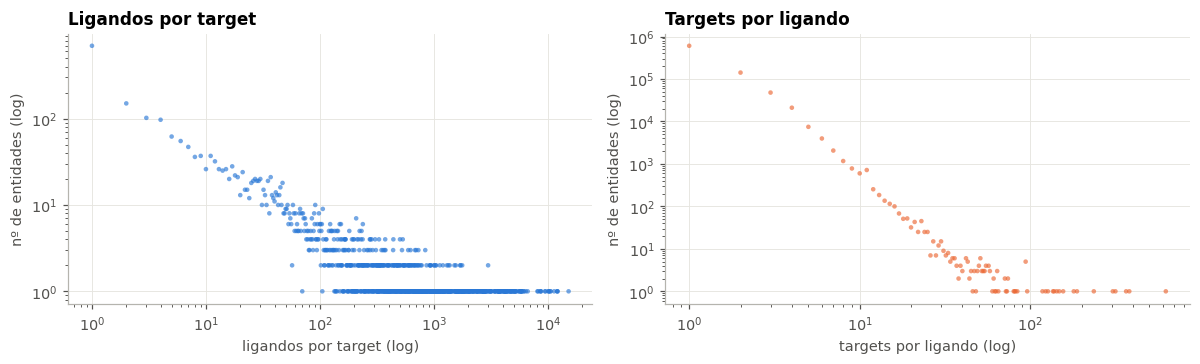

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, serie, etq, color in [(axes[0], lig_por_tgt, "ligandos por target", AZUL),
                              (axes[1], tgt_por_lig, "targets por ligando", NARANJA)]:
    vc = serie.value_counts().sort_index()
    ax.scatter(vc.index, vc.values, s=9, color=color, alpha=.65, edgecolors="none")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(etq + " (log)"); ax.set_ylabel("nº de entidades (log)")
    ax.set_title(etq.capitalize())
guardar(fig, "03_matriz")

**Interpretación.** En escala log–log, *targets por ligando* (derecha) es casi una recta, la firma de una **cola larga**: la gran mayoría de los ligandos aparece contra un solo target y un puñado de compuestos promiscuos llega a cientos. *Ligandos por target* (izquierda) decae igual de rápido, pero se aplana en el suelo de `y = 1` porque solo hay 3,444 targets: a partir de cierto punto, cada valor alto corresponde a un único target y los puntos dejan de alinearse. La asimetría entre los dos paneles es en sí misma informativa: hay 242 ligandos por cada target, así que la matriz es larguísima y angosta.

Esto tiene dos consecuencias para el modelo, y conviene que queden dichas aquí porque se derivan de los datos, no del algoritmo:

1. **El arranque en frío no es un caso borde, es el caso típico.** Casi tres cuartas partes de los ligandos se midieron contra un solo target, así que no tienen con quién compararse por co-ocurrencia. Un modelo puramente colaborativo no puede decir nada sobre ellos, y de ahí que la parte de contenido no sea un adorno del híbrido sino su razón de ser.
2. **Una partición aleatoria va a mentir.** Como los análogos de un mismo artículo son casi idénticos entre sí, repartirlos al azar entre entrenamiento y prueba deja copias del test en el train. Las columnas `anio_min` y `anio_max` están en la entrega precisamente para poder partir por tiempo (con la salvedad de que un 3% de los pares no tiene fecha), y `lig_id` permite partir por ligando nuevo.

Un subconjunto denso, si hace falta para los primeros experimentos, se obtiene con un *k-core* en tres líneas; se deja como sugerencia y **no** se aplica a la entrega, para no decidir por quien modela:

```python
I_core = I.copy()
for _ in range(10):   # iterar porque cada poda puede dejar nuevos nodos por debajo del mínimo
    I_core = I_core[I_core.groupby("lig_id").lig_id.transform("size") >= 5]
    I_core = I_core[I_core.groupby("target_id").target_id.transform("size") >= 20]
```

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">10. Escritura de la entrega</span></div>

In [19]:
I.to_parquet(OUT_INT, index=False)
L.to_parquet(OUT_LIG, index=False)
T.to_parquet(OUT_TGT, index=False)

meta = {
    "generado": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
    "fuente": str(EDA_CACHE),
    "parametros": {"MEDICION": MEDICION, "ESPECIE": ESPECIE, "SOLO_1_CADENA": SOLO_1_CADENA,
                   "UMBRAL": UMBRAL, "P_MIN": P_MIN, "P_MAX": P_MAX,
                   "LIG_ID_LEN": LIG_ID_LEN, "RANGO_DISC": RANGO_DISC},
    "embudo": [{"paso": k, "filas": int(v)} for k, v in EMBUDO],
    "salida": {"pares": len(I), "targets": len(T), "ligandos": len(L),
               "densidad_pct": round(100 * densidad, 6),
               "activos_pct": round(pct((I.activo == 1).sum(), len(I)), 2),
               "solo_censurado_pct": round(pct(I.solo_censurado.sum(), len(I)), 2),
               "discordantes_pct": round(pct(I.discordante.sum(), (I.n_exactas > 1).sum()), 2)},
}
OUT_META.write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")

for f in [OUT_INT, OUT_LIG, OUT_TGT, OUT_META]:
    print(f"  {str(f):46} {f.stat().st_size/1e6:7.1f} MB")

  data\processed\rec_interacciones.parquet          30.3 MB
  data\processed\rec_ligandos.parquet               83.5 MB
  data\processed\rec_targets.parquet                 2.5 MB
  data\processed\rec_meta.json                       0.0 MB


### 10.1 Diccionario de columnas

**`rec_interacciones.parquet`** — una fila por par proteína–ligando. Es la matriz.

| Columna | Tipo | Significado |
|---|---|---|
| `target_id` | texto | **Usuario.** Accession de UniProt de la proteína. Une con `rec_targets.parquet`. |
| `lig_id` | texto | **Ítem.** InChIKey recortado a 25 caracteres. Une con `rec_ligandos.parquet`. |
| `pIC50` | float | **Rating continuo.** `9 − log₁₀(IC50 nM)`; más grande = más potente. Mediana de las mediciones exactas. **Nulo** si el par solo tiene cotas. |
| `activo` | 0/1 | **Rating binario.** 1 si `pIC50 ≥ 6`, o si las cotas lo concluyen. Nunca es nulo. |
| `n_mediciones` | int | Veces que se midió el par. |
| `n_exactas` / `n_censuradas` | int | Desglose de las anteriores. Suman `n_mediciones`. |
| `pIC50_min` / `pIC50_max` | float | Extremos de las mediciones exactas del par. |
| `rango_log` | float | `pIC50_max − pIC50_min`: el desacuerdo experimental del par. |
| `discordante` | bool | `rango_log > 1`. Candidatos a ponderar menos o excluir. |
| `solo_censurado` | bool | El par no tiene ningún valor puntual; `pIC50` es nulo y solo sirve `activo`. |
| `conflicto_cotas` | bool | Cotas que se contradicen entre sí. Muy pocos; conviene revisarlos o excluirlos. |
| `anio_min` / `anio_max` | Int16 | Año de publicación más antiguo y más reciente del par. **Para la partición temporal.** Nulo en ~3% de los pares, que no traían fecha válida. |
| `alguna_patente` | bool | Al menos una medición viene de una patente. Para controlar el sesgo de fuente. |

**`rec_ligandos.parquet`** — atributos de ítem: `lig_id`, `smiles` (para los *fingerprints*), `inchikey`, `nombre`, `id_cid`, `id_chembl`, `n_targets`, `n_mediciones`.

**`rec_targets.parquet`** — atributos de usuario: `target_id`, `entry_name`, `nombre`, `secuencia` (para los descriptores de proteína), `longitud`, `n_nombres_bdb`, `n_ligandos`, `n_mediciones`. Ojo con la advertencia de la sección 7.2 antes de calcular descriptores de secuencia.

> Los tres archivos viven en `data/processed/`, que está en `.gitignore` porque el volcado original pesa 9 GB. **No se reciben clonando el repositorio**: hay que pasarlos por separado, o regenerarlos corriendo primero `BindingDB_EDA.ipynb` y luego este notebook.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">11. Resumen</span></div>

La tabla se genera a partir de las variables calculadas arriba, sin números escritos a mano.

In [20]:
display(pd.Series(H, name="valor").to_frame())

emb = pd.DataFrame(EMBUDO, columns=["paso", "filas"])
emb["% del inicio"] = (100 * emb["filas"] / emb["filas"].iloc[0]).round(1)
emb["pierde"] = (emb["filas"].shift() - emb["filas"]).fillna(0).astype(int)
display(emb.style.format({"filas": "{:,}", "pierde": "{:,}", "% del inicio": "{:.1f}"})
         .hide(axis="index"))

,valor
Filas humanas que un filtro por texto perdería,"165,017"
Negativos explícitos recuperados de los censurados,"214,162"
Targets (usuarios),"3,444"
Ligandos (ítems),"832,751"
Pares (celdas con dato),"1,250,494"
Pares cuyo único dato es una cota,20.7%
Pares discordantes (de los repetidos),19.8%
Densidad de la matriz,0.04360%
Ligandos con un solo target,72.6%


paso,filas,% del inicio,pierde
Filas en el EDA,"3,243,660",100.0,0
Con IC50 medido,"2,220,490",68.5,"1,023,170"
Target de la especie HUMAN,"1,908,487",58.8,"312,003"
Proteína de una sola cadena,"1,784,544",55.0,"123,943"
Accession UniProt válida,"1,784,542",55.0,2
InChIKey con formato válido,"1,784,334",55.0,208
IC50 > 0,"1,784,179",55.0,155
"p dentro de [2.0, 12.0]","1,782,559",55.0,"1,620"
Sin censurados no concluyentes,"1,758,349",54.2,"24,210"


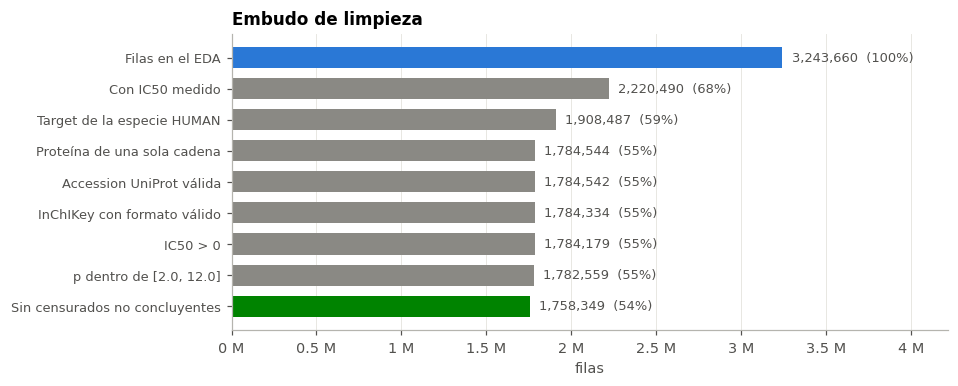

In [21]:
fig, ax = plt.subplots(figsize=(8.8, 3.6))
y = np.arange(len(emb))[::-1]
ax.barh(y, emb["filas"], color=[AZUL] + [GRIS]*(len(emb)-2) + [VERDE], height=0.68)
for yi, (f, p) in zip(y, zip(emb["filas"], emb["% del inicio"])):
    ax.annotate(f"{f:,}  ({p:.0f}%)", xy=(f, yi), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8.5, color="#52514e")
ax.set_yticks(y); ax.set_yticklabels(emb["paso"], fontsize=8.5)
ax.set_xlim(0, emb["filas"].max()*1.3)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e6:g} M"))
ax.set_xlabel("filas"); ax.set_title("Embudo de limpieza")
ax.grid(axis="y", visible=False)
guardar(fig, "04_embudo")

**Lectura del embudo.** De los 3.2 millones de mediciones del volcado completo se entregan 1.25 millones de pares. Las dos podas grandes son deliberadas y no son "suciedad": quedarse con **IC50** descarta casi un tercio del archivo (el millón de filas que traen Ki, Kd o EC50, que el EDA §5, *Medición por fila* mostró que vienen una por fila), y quedarse con **proteínas humanas de una sola cadena** descarta un 20% adicional.

En contraste, los filtros de **calidad** —formato de accession, formato de InChIKey, valores imposibles, cotas no concluyentes— se llevan menos del 2% en conjunto. Vale la pena señalarlo: el dataset está **limpio en el sentido de formato** y lo verdaderamente delicado no era corregir celdas corruptas, sino tomar bien las decisiones de modelado que estaban disfrazadas de limpieza —qué cuenta como usuario, qué hacer con una cota y cómo colapsar mediciones que se contradicen.

### Qué queda abierto para quien modele

- **Los *fingerprints* moleculares.** Requieren RDKit (`pip install rdkit`), que no está en este entorno. La materia prima (`smiles`) va en `rec_ligandos.parquet`.
- **El umbral de actividad.** Se entregó con `pIC50 ≥ 6` (1 µM), el corte habitual, y da clases balanceadas. Con 7 (100 nM) el criterio es más exigente y la clase positiva se encoge.
- **Qué hacer con los 42 mil pares discordantes.** Están marcados, no eliminados.
- **La partición.** `anio_min` permite la temporal y `lig_id` la de ligandos nuevos. Una partición aleatoria infla los resultados por los análogos de un mismo artículo.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Referencias</span></div>

Las referencias de biología, química y de la propia base de datos están en la sección 12 de `BindingDB_EDA.ipynb`. Las citas de la forma `EDA §n, *título*` remiten a sus secciones y subsecciones. Aquí solo se agregan las tres fuentes que se usan en la limpieza y que no aparecen allá.

1. BindingDB. *Download* (release 202611). <https://www.bindingdb.org/rwd/bind/chemsearch/marvin/Download.jsp>
2. UniProt Consortium. *What is the canonical accession number format?* — patrón oficial de las accessions y estructura del *entry name* (`XXXX_HUMAN`). <https://www.uniprot.org/help/accession_numbers>
3. UniProt Consortium. *Sequence annotation: non-standard amino acids* — la `U` codifica selenocisteína. <https://www.uniprot.org/help/non_std>